# Graph coloring with Z3

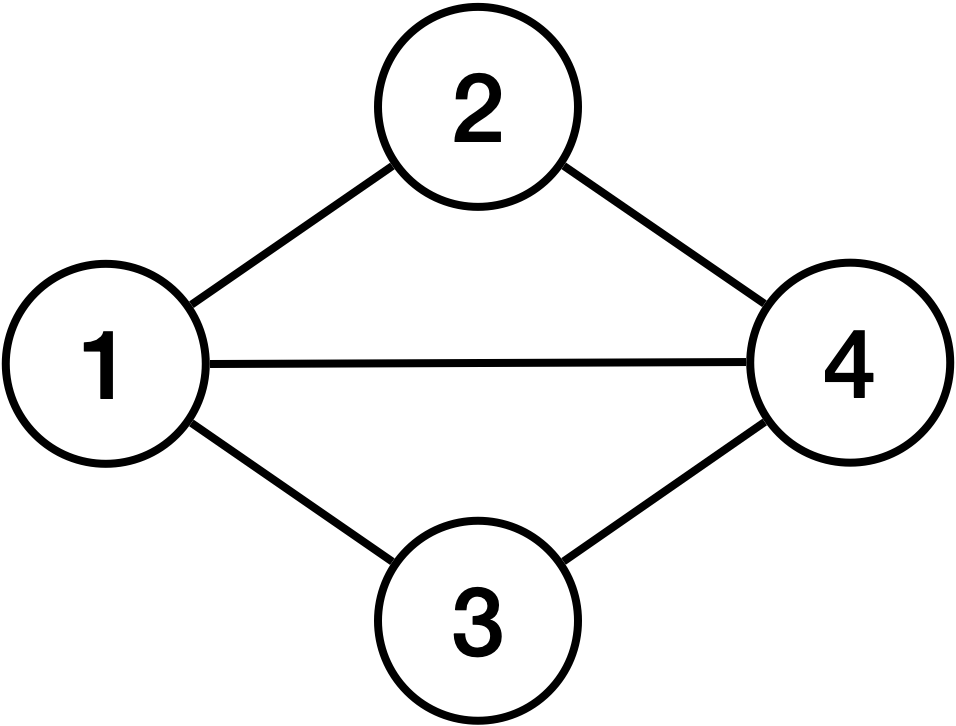

In [ ]:
!pip install z3-solver

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 33.1/33.1 MB 24.7 MB/s eta 0:00:00


In [ ]:
# Can the graph be colored with 3 colors?

from z3 import *
from itertools import combinations

Vertex = range(1, 5)
adj = [(1,2),(1,3),(1,4),(2,4),(3,4)]
Color = ["red", "green", "blue"]

vars = {}
for v in Vertex:
    for c in Color:
        vars[(v,c)] = Bool(f"v{v}_{c}")

s = Solver()

# at least one color per vertex

for v in Vertex:
    s.add(Or([vars[(v,c)] for c in Color]))

# at most one color per vertex

for v in Vertex:
    for c1, c2 in combinations(Color, 2):
        s.add(Not(And(vars[(v,c1)], vars[(v,c2)])))

# adjacent vertices cannot have the same color

for (v1, v2) in adj:
    for c in Color:
        s.add(Not(And(vars[(v1,c)], vars[(v2,c)])))

print("It is possible to color the graph with the given colors.")
if s.check() == sat:
    m = s.model()
    for v in Vertex:
        for c in Color:
            if m[vars[(v,c)]]:
                print(f"Vertex {v} is colored {c}")
else:
    print("It is not possible to color the graph with the given colors.")

It is possible to color the graph with the given colors.
Vertex 1 is colored blue
Vertex 2 is colored red
Vertex 3 is colored red
Vertex 4 is colored green


In [ ]:
# How many different colorings exist?

# create a new frame of the solver stack to store new constraints
s.push()

i = 1
while s.check() == sat:
    m = s.model()
    coloring = []
    for v in Vertex:
        for c in Color:
            if m[vars[(v,c)]]:
                coloring.append((v, c))
    print(f"Coloring {i}: {coloring}")
    i += 1
    # add a constraint to block the current coloring
    s.add(Not(And([vars[(v,c)] for (v,c) in coloring])))

# remove the added constraint
s.pop()


Coloring 1: [(1, 'blue'), (2, 'red'), (3, 'red'), (4, 'green')]
Coloring 2: [(1, 'green'), (2, 'red'), (3, 'red'), (4, 'blue')]
Coloring 3: [(1, 'red'), (2, 'green'), (3, 'green'), (4, 'blue')]
Coloring 4: [(1, 'blue'), (2, 'green'), (3, 'green'), (4, 'red')]
Coloring 5: [(1, 'red'), (2, 'blue'), (3, 'blue'), (4, 'green')]
Coloring 6: [(1, 'green'), (2, 'blue'), (3, 'blue'), (4, 'red')]


In [ ]:
# Is it always true that vertexes 2 and 3 always have the same color?

s.push()

prop = Or([And(vars[(2,c)], vars[(3,c)]) for c in Color])

s.add(Not(prop))
if s.check() == unsat:
    print("Vertices 2 and 3 always have the same color.")
else:
    print("Vertices 2 and 3 might have different colors.")

s.pop()

Vertices 2 and 3 always have the same color.
